**Name:** Mingze Geng  
**GitHub username:** Mingze88  
**USC ID:** 1418612987

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [10]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
import statsmodels.api as sm

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_rows', 100)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})
RANDOM_SEED = 552

In [11]:

DATA_DIR = Path('data/AReM')
series_names = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13',
                'avg_rss23', 'var_rss23']
activities = ['bending1', 'bending2', 'cycling', 'lying',
              'sitting', 'standing', 'walking']
expected_counts = dict(zip(activities, [7, 6, 15, 15, 15, 15, 15]))

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f'{DATA_DIR} was not found. Keep the data/AReM folder next to this notebook.'
    )
recordings = {}
audit = []
for activity in activities:
    files = sorted((DATA_DIR / activity).glob('dataset*.csv'),
                   key=lambda p: int(re.search(r'dataset(\d+)', p.name).group(1)))
    if len(files) != expected_counts[activity]:
        raise ValueError(f'{activity}: expected {expected_counts[activity]} CSV files, found {len(files)}')
    for path in files:
        number = int(re.search(r'dataset(\d+)', path.name).group(1))
        rows = []
        for line in path.read_text(encoding='utf-8-sig').splitlines():
            line = line.strip().rstrip(',')
            if not line or line.startswith('#'):
                continue
            rows.append(re.split(r'[ ,\t]+', line))
        values = np.asarray(rows, dtype=float)
        if values.ndim != 2 or values.shape[1] != 7 or not np.isfinite(values).all():
            raise ValueError(f'Unexpected CSV format in {path}')
        timestamps = values[:, 0]
        if len(np.unique(timestamps)) != len(timestamps) or not np.all(np.diff(timestamps) > 0):
            raise ValueError(f'Invalid timestamps in {path}')
        recordings[(activity, number)] = pd.DataFrame(values[:, 1:], columns=series_names)
        audit.append({'activity': activity, 'dataset': number, 'rows': len(values)})
assert len(recordings) == 88

audit_df = pd.DataFrame(audit).sort_values(['activity', 'dataset'])
display(audit_df.groupby('activity').agg(instances=('dataset', 'size'),
                                          min_rows=('rows', 'min'),
                                          max_rows=('rows', 'max')))

,instances,min_rows,max_rows
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


### (b) Test and Train Data

**Data-quality note:** The supplied `sitting/dataset8.csv` contains 479 observed
rows; the other 87 recordings contain 480. I retain the available observations
without adding an artificial row. Segmenting with `np.array_split` uses all
observations and produces segment lengths differing by at most one sample.


In [13]:
def is_test(activity, number):
    return number <= (2 if activity in ['bending1', 'bending2'] else 3)

split_rows = [{'activity': a, 'dataset': n,
               'split': 'test' if is_test(a, n) else 'train'}
              for a, n in recordings]
split_df = pd.DataFrame(split_rows).sort_values(['activity', 'dataset'])
split_summary = pd.crosstab(split_df['activity'], split_df['split'])
display(split_summary[['train', 'test']])
assert (split_df['split'] == 'train').sum() == 69
assert (split_df['split'] == 'test').sum() == 19
train_keys = {(a, n) for a, n in recordings if not is_test(a, n)}
test_keys = set(recordings) - train_keys
assert train_keys.isdisjoint(test_keys)
print('69 training instances; 19 test instances. Split by recording, not by time point.')


split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


69 training instances; 19 test instances. Split by recording, not by time point.


### (c) Feature Extraction

#### i. Research




| Type | Common features | What they describe |
|---|---|---|
| Location | Mean, median, quantiles | Typical signal level |
| Extremes | Minimum, maximum, range | Bounds and amplitude span |
| Dispersion | Standard deviation, variance, interquartile range | Variation in signal values |
| Distribution shape | Skewness, kurtosis | Asymmetry and tail behavior |
| Magnitude | Root mean square, sum of squares (energy) | Signal magnitude |
| Temporal changes | Mean absolute successive difference, linear trend, threshold crossings, peak count | Changes and movement over time |
| Dependence and complexity | Autocorrelation at specified lags, sample entropy | Repetition, dependence, and irregularity |



#### ii. Extraction

In [18]:
statistics = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']
feature_columns = [f'{stat}{j}' for j in range(1, 7) for stat in statistics]

def extract_features(frame):
    result = {}
    for j, name in enumerate(series_names, start=1):
        x = frame[name].to_numpy()
        values = [np.min(x), np.max(x), np.mean(x), np.median(x),
                  np.std(x, ddof=1),
                  np.quantile(x, 0.25, method='linear'),
                  np.quantile(x, 0.75, method='linear')]
        result.update({f'{s}{j}': v for s, v in zip(statistics, values)})
    return result

records = []
for instance, ((activity, number), frame) in enumerate(
        sorted(recordings.items()), start=1):
    records.append({'instance': instance, 'activity': activity,
                    'dataset': number,
                    'split': 'test' if is_test(activity, number) else 'train',
                    **extract_features(frame)})
features = pd.DataFrame(records)
X = features.set_index('instance')[feature_columns]
train_features = features.loc[features['split'] == 'train'].copy()
test_features = features.loc[features['split'] == 'test'].copy()
assert X.shape == (88, 42)
assert np.isfinite(X.to_numpy()).all()

display(Markdown('**All 88 instances × 42 extracted features:**'))
display(X)
display(Markdown('**Sample metadata and feature values:**'))
display(features.head())
print('42 = 7 statistics × 6 sensor series; timestamp is not a predictor.')


**All 88 instances × 42 extracted features:**

,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,median2,std2,q12,q32,min3,max3,mean3,median3,std3,q13,q33,min4,max4,mean4,median4,std4,q14,q34,min5,max5,mean5,median5,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.6248,40.500,1.4770,39.2500,42.0000,0.0,1.30,0.3586,0.430,0.3226,0.0000,0.5000,4.00,29.50,19.0409,19.250,4.4630,16.0000,23.2500,0.0,7.23,0.8325,0.500,0.9657,0.0000,1.1200,27.25,38.25,34.3113,35.000,2.1884,33.0000,36.0000,0.00,1.92,0.5706,0.430,0.5829,0.0000,1.3000
2,38.00,45.67,42.8128,42.500,1.4355,42.0000,43.6700,0.0,1.22,0.3724,0.470,0.2892,0.0000,0.5000,2.00,29.50,20.0970,21.000,3.8937,19.0000,22.2500,0.0,5.76,0.8764,0.500,1.0473,0.0000,1.1450,27.67,38.50,33.0246,33.000,1.9953,32.0000,34.5000,0.00,3.11,0.5711,0.430,0.6010,0.0000,1.3000
3,35.00,47.40,43.9545,44.330,1.5588,43.0000,45.0000,0.0,1.70,0.4263,0.470,0.3387,0.0000,0.5000,6.50,29.75,22.1224,23.000,3.0309,19.7500,24.0000,0.0,4.44,0.4973,0.430,0.5507,0.0000,0.8300,29.00,38.50,35.5885,36.000,1.9996,35.3625,36.5000,0.00,1.79,0.4933,0.430,0.5135,0.0000,0.9400
4,33.00,47.75,42.1798,43.500,3.6707,39.1500,45.0000,0.0,3.00,0.6960,0.500,0.6309,0.0000,1.1200,8.50,30.00,22.1836,23.000,3.8105,20.5000,24.3725,0.0,5.15,0.9899,0.830,0.9537,0.4300,1.3000,20.00,38.67,33.4939,35.000,3.8494,30.4575,36.3300,0.00,2.18,0.6135,0.500,0.5243,0.0000,1.0000
5,33.00,45.75,41.6781,41.750,2.2435,41.3300,42.7500,0.0,2.83,0.5360,0.500,0.4055,0.4300,0.7100,3.00,28.25,19.0066,19.125,4.0871,16.5000,22.0625,0.0,6.42,0.8419,0.500,0.9288,0.4300,1.1200,23.67,37.50,29.8571,30.000,2.4110,28.4575,31.2500,0.00,1.79,0.3833,0.430,0.3892,0.0000,0.5000
6,37.00,48.00,43.4550,43.250,1.3861,42.5000,45.0000,0.0,1.58,0.3781,0.470,0.3156,0.0000,0.5000,5.75,27.00,15.7933,15.000,3.8476,13.0000,18.2700,0.0,10.03,0.8494,0.500,0.9958,0.4300,1.1200,8.00,33.50,23.0348,23.500,2.4889,22.2500,24.0000,0.00,5.26,0.6796,0.500,0.6225,0.4300,0.8700
7,36.25,48.00,43.9691,44.500,1.6184,43.3100,44.6700,0.0,1.50,0.4131,0.470,0.2631,0.4300,0.5000,1.50,26.33,15.8680,16.250,3.7424,14.2500,18.0000,0.0,5.17,0.6664,0.470,0.7890,0.0000,0.9400,11.33,30.75,22.1038,21.670,3.3183,20.5000,23.7500,0.00,2.96,0.5553,0.490,0.4878,0.0000,0.8300
8,12.75,51.00,24.5630,24.250,3.7375,23.1875,26.5000,0.0,6.87,0.5908,0.430,0.8374,0.0000,0.7100,0.00,25.33,19.1213,20.250,4.2996,18.0000,22.0000,0.0,6.76,0.7368,0.470,0.9270,0.0000,0.8700,10.67,30.00,23.4930,23.750,3.6938,20.5000,27.0000,0.00,4.97,0.7002,0.500,0.6937,0.4300,0.8700
9,0.00,42.75,27.4646,28.000,3.5836,25.5000,30.0000,0.0,7.76,0.4497,0.430,0.7672,0.0000,0.5000,7.50,35.00,20.8425,20.750,3.8263,18.0000,22.5000,0.0,5.76,0.7799,0.500,0.9044,0.0000,0.9400,0.00,33.00,17.6179,18.000,5.0536,15.0000,20.7500,0.00,6.76,1.1221,0.830,1.0123,0.4700,1.3000


**Sample metadata and feature values:**

,instance,activity,dataset,split,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,median2,std2,q12,q32,min3,max3,mean3,median3,std3,q13,q33,min4,max4,mean4,median4,std4,q14,q34,min5,max5,mean5,median5,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,1,bending1,1,test,37.25,45.00,40.6248,40.50,1.4770,39.25,42.00,0.0,1.30,0.3586,0.43,0.3226,0.00,0.50,4.0,29.50,19.0409,19.250,4.4630,16.00,23.2500,0.0,7.23,0.8325,0.50,0.9657,0.00,1.120,27.25,38.25,34.3113,35.0,2.1884,33.0000,36.00,0.0,1.92,0.5706,0.43,0.5829,0.0,1.30
1,2,bending1,2,test,38.00,45.67,42.8128,42.50,1.4355,42.00,43.67,0.0,1.22,0.3724,0.47,0.2892,0.00,0.50,2.0,29.50,20.0970,21.000,3.8937,19.00,22.2500,0.0,5.76,0.8764,0.50,1.0473,0.00,1.145,27.67,38.50,33.0246,33.0,1.9953,32.0000,34.50,0.0,3.11,0.5711,0.43,0.6010,0.0,1.30
2,3,bending1,3,train,35.00,47.40,43.9545,44.33,1.5588,43.00,45.00,0.0,1.70,0.4263,0.47,0.3387,0.00,0.50,6.5,29.75,22.1224,23.000,3.0309,19.75,24.0000,0.0,4.44,0.4973,0.43,0.5507,0.00,0.830,29.00,38.50,35.5885,36.0,1.9996,35.3625,36.50,0.0,1.79,0.4933,0.43,0.5135,0.0,0.94
3,4,bending1,4,train,33.00,47.75,42.1798,43.50,3.6707,39.15,45.00,0.0,3.00,0.6960,0.50,0.6309,0.00,1.12,8.5,30.00,22.1836,23.000,3.8105,20.50,24.3725,0.0,5.15,0.9899,0.83,0.9537,0.43,1.300,20.00,38.67,33.4939,35.0,3.8494,30.4575,36.33,0.0,2.18,0.6135,0.50,0.5243,0.0,1.00
4,5,bending1,5,train,33.00,45.75,41.6781,41.75,2.2435,41.33,42.75,0.0,2.83,0.5360,0.50,0.4055,0.43,0.71,3.0,28.25,19.0066,19.125,4.0871,16.50,22.0625,0.0,6.42,0.8419,0.50,0.9288,0.43,1.120,23.67,37.50,29.8571,30.0,2.4110,28.4575,31.25,0.0,1.79,0.3833,0.43,0.3892,0.0,0.50


42 = 7 statistics × 6 sensor series; timestamp is not a predictor.


#### iii. Standard Deviation

,feature,sample_sd,ci90_lower,ci90_upper
0,min1,9.5700,8.2622,10.7614
1,max1,4.3944,3.3280,5.2849
2,mean1,5.3357,4.7040,5.8864
3,median1,5.4401,4.7903,6.0043
4,std1,1.7722,1.5722,1.9500
5,q11,6.1536,5.5816,6.6524
6,q31,5.1389,4.3319,5.8409
7,min2,0.0000,0.0000,0.0000
8,max2,5.0627,4.6228,5.4022
9,mean2,1.5742,1.3941,1.7068


Percentile bootstrap: 10,000 resamples; seed=552; ddof=1.


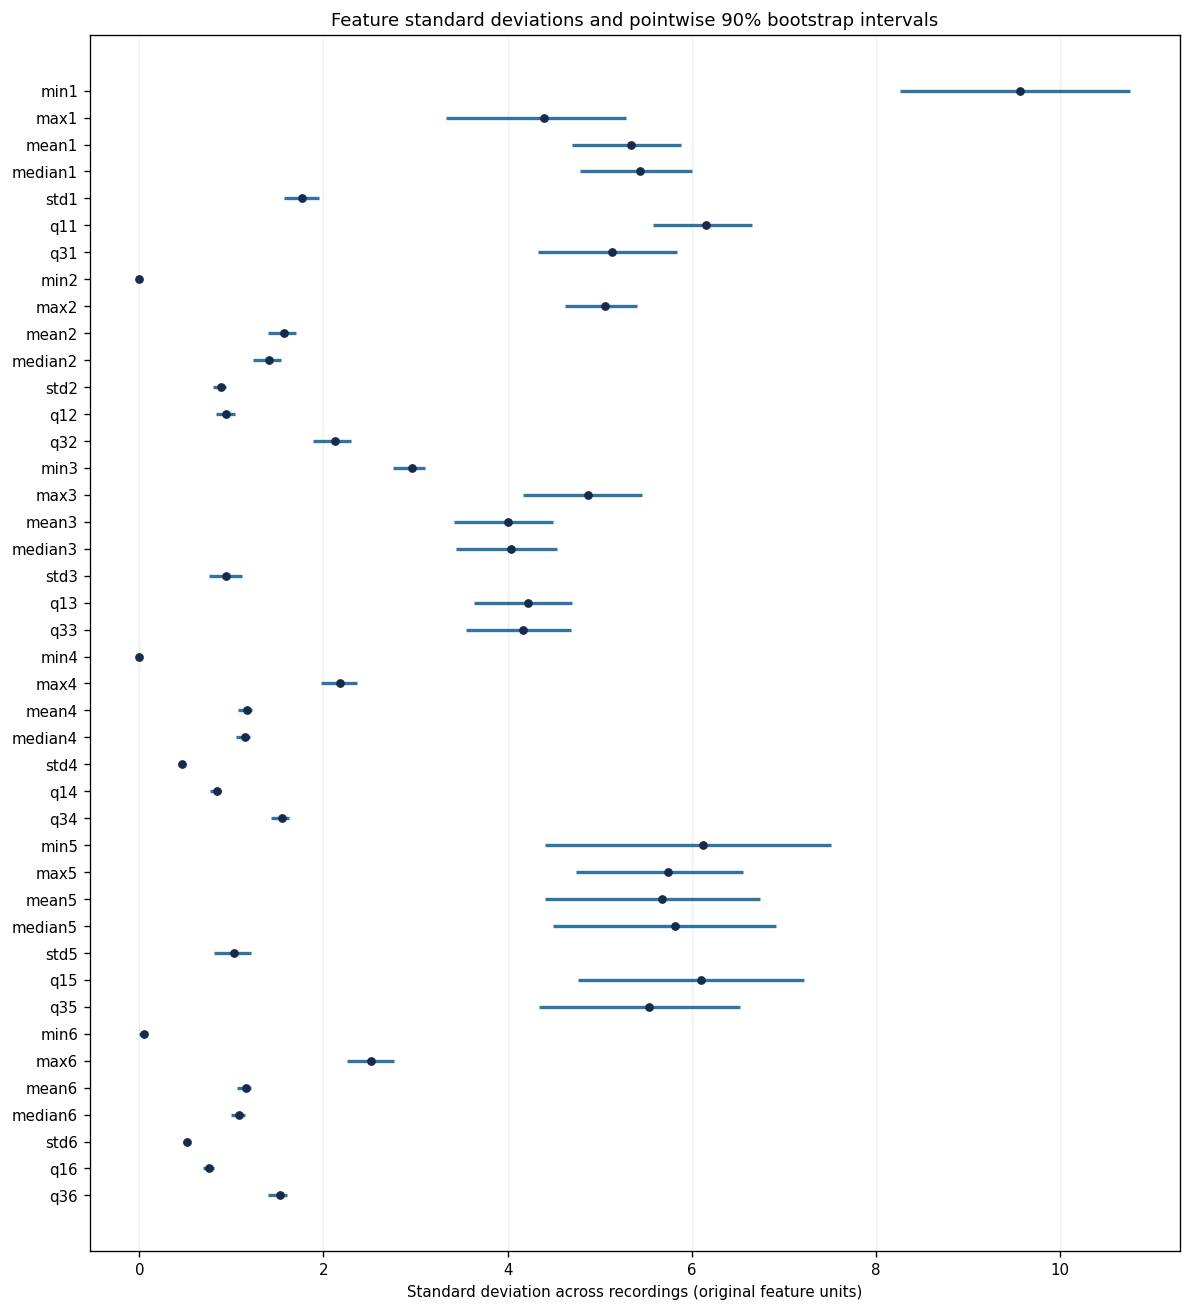

In [20]:
# This SD measures variation of each extracted feature ACROSS recordings.
# It is different from the within-recording std1, ..., std6 features.
values = X.to_numpy()
n, p = values.shape
feature_sd = np.std(values, axis=0, ddof=1)
B = 10000
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_sd = np.empty((B, p))
batch_size = 250
for start in range(0, B, batch_size):
    stop = min(start + batch_size, B)
    # Resample complete recording rows to preserve relationships among features.
    indices = rng.integers(0, n, size=(stop-start, n))
    bootstrap_sd[start:stop] = np.std(values[indices], axis=1, ddof=1)
lower, upper = np.quantile(bootstrap_sd, [0.05, 0.95], axis=0)
sd_ci = pd.DataFrame({'feature': feature_columns,
                      'sample_sd': feature_sd,
                      'ci90_lower': lower,
                      'ci90_upper': upper})
assert len(sd_ci) == 42
assert np.all(lower <= upper)
display(sd_ci)
print(f'Percentile bootstrap: {B:,} resamples; seed={RANDOM_SEED}; ddof=1.')

fig, ax = plt.subplots(figsize=(10, 11))
y = np.arange(p)
ax.hlines(y, lower, upper, color='#3274a1', linewidth=2)
ax.scatter(feature_sd, y, color='#172b4d', s=18, zorder=3)
ax.set_yticks(y, feature_columns)
ax.invert_yaxis()
ax.set_xlabel('Standard deviation across recordings (original feature units)')
ax.set_title('Feature standard deviations and pointwise 90% bootstrap intervals')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()


For each feature, I calculate the sample standard deviation across the 88 recordings. For each of 10,000 bootstrap samples, I draw 88 recordings with replacement and recalculate all 42 standard deviations.

The 5th and 95th percentiles of the bootstrap results give a pointwise 90% confidence interval for each feature’s standard deviation. I resample whole recordings, not individual time points. This treats the recordings as independent draws from the pooled activity data.

These intervals describe uncertainty in each feature’s standard deviation. They do not show where 90% of individual feature values fall. They are not simultaneous confidence intervals for all 42 features.

I use all 88 recordings for this descriptive calculation. I do not use these results to fit or tune a classifier on the held-out test set.

#### iv. Select Features

1. Mean summarizes the typical RSS level. Sensor position and body posture can change that level.
2. Standard deviation captures variation during the activity. It may help distinguish steady postures from repeated movement.
3. Maximum captures a high signal level. It may show an extreme change that the mean does not capture.

These features describe the signal’s level, variation, and extremes. Some features, such as the mean and median, may provide similar information. The maximum can be sensitive to outliers, so a later model should assess its usefulness with training data only. A feature’s large standard deviation across recordings does not prove that it is important. Features can use different scales.


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a)(i) 

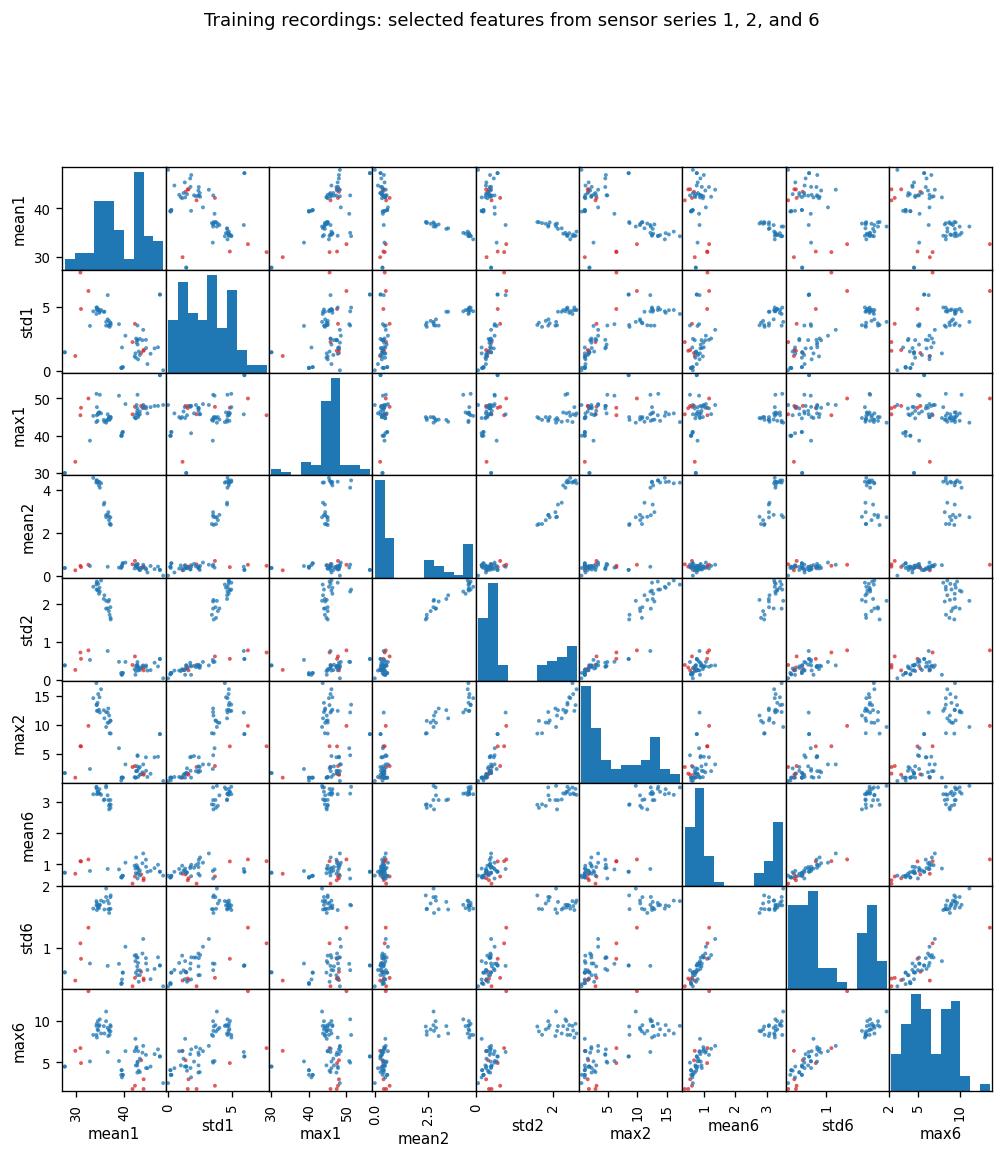

Features: ['mean1', 'std1', 'max1', 'mean2', 'std2', 'max2', 'mean6', 'std6', 'max6']
Red = bending; blue = other activities.


In [35]:

selected_plot_features = [f'{stat}{j}' for j in [1, 2, 6]
                          for stat in ['mean', 'std', 'max']]
plot_data = features.loc[features['split'] == 'train'].copy()
plot_data['label'] = np.where(plot_data['activity'].isin(['bending1', 'bending2']),
                              'bending', 'other')
colors = plot_data['label'].map({'bending': '#d62728', 'other': '#1f77b4'})
from pandas.plotting import scatter_matrix
axes = scatter_matrix(plot_data[selected_plot_features], figsize=(10, 10),
                      diagonal='hist', c=colors, alpha=.75, s=22)
plt.suptitle('Training recordings: selected features from sensor series 1, 2, and 6', y=1.01)
plt.show()
print('Features:', selected_plot_features)
print('Red = bending; blue = other activities.')

### 2(a)(ii) 


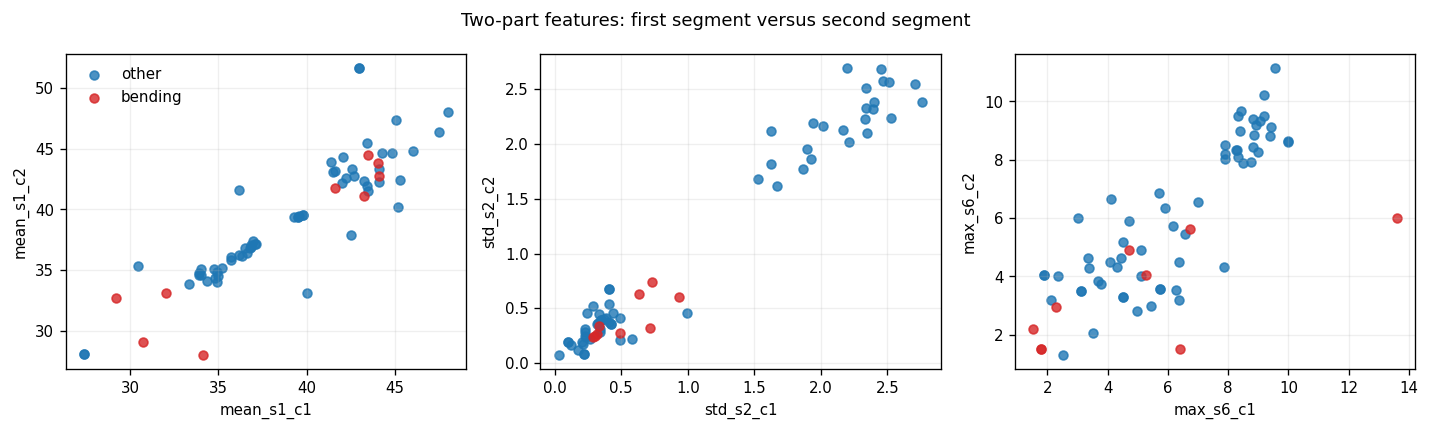

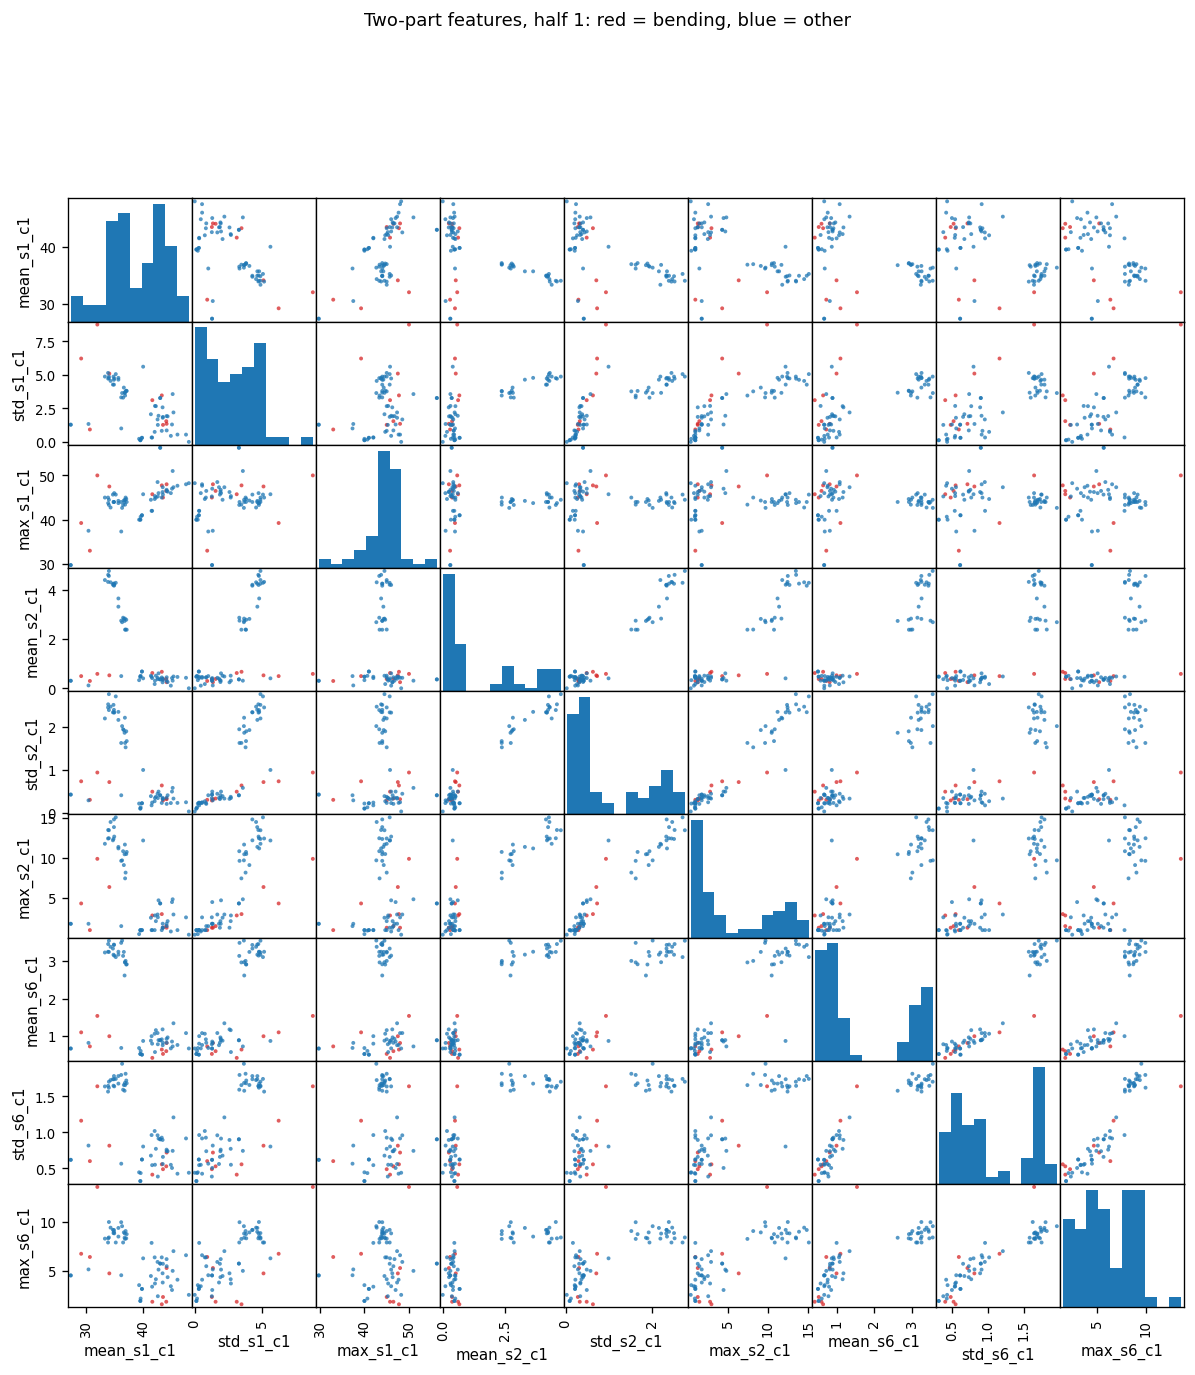

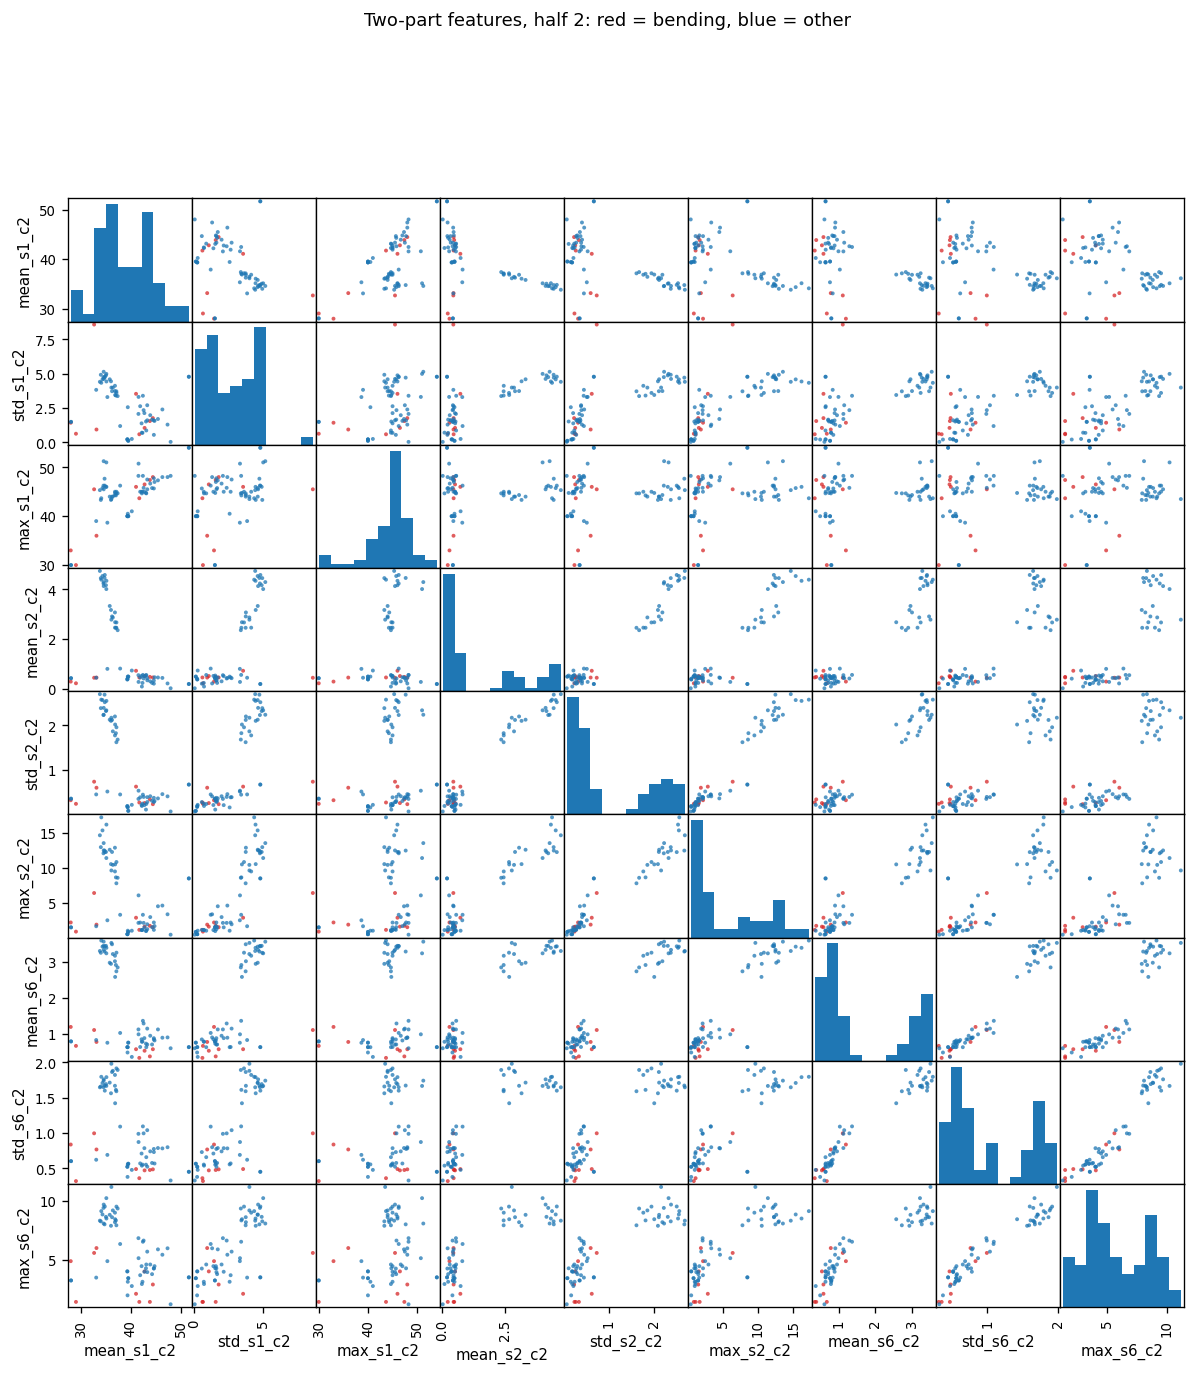

In [37]:
def segment_matrix(keys, n_chunks, series_indices=range(1, 7)):
    """One feature row per recording; summarize each equal-length segment."""
    rows, labels, metadata = [], [], []
    for activity, number in sorted(keys):
        frame = recordings[(activity, number)]
        row = {}
        for j in series_indices:
            values = frame[series_names[j-1]].to_numpy()
            chunks = np.array_split(values, n_chunks)
            for c, chunk in enumerate(chunks, start=1):
                row[f'mean_s{j}_c{c}'] = float(np.mean(chunk))
                row[f'std_s{j}_c{c}'] = float(np.std(chunk, ddof=1))
                row[f'max_s{j}_c{c}'] = float(np.max(chunk))
        rows.append(row)
        labels.append(int(activity in ['bending1', 'bending2']))
        metadata.append({'activity': activity, 'dataset': number})
    return pd.DataFrame(rows), np.asarray(labels), pd.DataFrame(metadata)

X2, y2, meta2 = segment_matrix(train_keys, 2, series_indices=[1, 2, 6])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
comparisons = [('mean_s1_c1', 'mean_s1_c2'),
               ('std_s2_c1', 'std_s2_c2'),
               ('max_s6_c1', 'max_s6_c2')]
for ax, (xcol, ycol) in zip(axes, comparisons):
    for label, color, name in [(0, '#1f77b4', 'other'), (1, '#d62728', 'bending')]:
        mask = y2 == label
        ax.scatter(X2.loc[mask, xcol], X2.loc[mask, ycol], color=color,
                   label=name, alpha=.8, s=28)
    ax.set_xlabel(xcol); ax.set_ylabel(ycol); ax.grid(alpha=.2)
axes[0].legend(frameon=False)
fig.suptitle('Two-part features: first segment versus second segment')
fig.tight_layout(); plt.show()

# Repeat the original nine-feature scatter matrix for EACH half. This includes
# mean, standard deviation, and maximum from series 1, 2, and 6 in both halves.
for half in [1, 2]:
    half_columns = [f'{stat}_s{j}_c{half}' for j in [1, 2, 6]
                    for stat in ['mean', 'std', 'max']]
    half_colors = np.where(y2 == 1, '#d62728', '#1f77b4')
    scatter_matrix(X2[half_columns], figsize=(12, 12), diagonal='hist',
                   c=half_colors, alpha=.75, s=22)
    plt.suptitle(f'Two-part features, half {half}: red = bending, blue = other', y=1.01)
    plt.show()

Each recording remains one observation: splitting produces 18 selected plotting
features instead of nine. The two matrices show the same three statistics for
series 1, 2, and 6 separately in the first and second halves. The additional
first-half-versus-second-half plots show changes within a recording.

Compared with the unsplit matrix, the broad pattern remains similar: bending
and other activities separate more clearly for some feature pairs than others,
and overlap remains. Splitting changes individual values and reveals temporal
variation, but does not make every pair perfectly separable. These training
plots alone do not establish that two segments improve generalization. I use
training cross-validation to choose the number of segments below.

### Helpers for the classification models

In [40]:
# The HW3 feature selection keeps mean, standard deviation, and maximum.
# For each l, each recording has 18*l features (3 statistics x 6 series x l chunks).
def all_segment_data(keys, l, binary=True):
    X, y, meta = segment_matrix(keys, l, series_indices=range(1, 7))
    if not binary:
        y = meta['activity'].to_numpy()
    return X, y, meta

train_keys_ordered = sorted(train_keys)
test_keys_ordered = sorted(test_keys)
Xb_full, y_train, meta_train = all_segment_data(train_keys_ordered, 1)
Xb_test_full, y_test, meta_test = all_segment_data(test_keys_ordered, 1)
assert len(y_train) == 69 and len(y_test) == 19
assert y_train.sum() == 9 and y_test.sum() == 4
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
print('Binary training class counts (other=0, bending=1):', np.bincount(y_train))
print('Binary test class counts (other=0, bending=1):', np.bincount(y_test))

def rfe_pipeline(p, l2_C=1e6):
    base = LogisticRegression(solver='liblinear', C=l2_C, max_iter=2000,
                              random_state=RANDOM_SEED)
    final = LogisticRegression(solver='liblinear', C=l2_C, max_iter=2000,
                               random_state=RANDOM_SEED)
    return make_pipeline(StandardScaler(),
                         RFE(base, n_features_to_select=p, step=0.5), final)

def binary_metrics(name, y_true, pred, prob):
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    print(f'{name}: accuracy={accuracy_score(y_true,pred):.3f}; '
          f'balanced accuracy={balanced_accuracy_score(y_true,pred):.3f}; '
          f'AUC={roc_auc_score(y_true,prob):.3f}')
    display(pd.DataFrame(cm, index=['actual other','actual bending'],
                         columns=['pred other','pred bending']))
    fpr, tpr, _ = roc_curve(y_true, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_true,prob):.3f})')
    plt.plot([0,1],[0,1],'k--',alpha=.5)
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
    plt.grid(alpha=.2)


Binary training class counts (other=0, bending=1): [60  9]
Binary test class counts (other=0, bending=1): [15  4]


### 2(a)(iii)


In [42]:
# Search l=1,...,20 and several p values. RFE is performed anew inside every fold.
selection_rows = []
for l in range(1, 21):
    X_l, y_l, _ = all_segment_data(train_keys_ordered, l)
    p_values = sorted(set([1, 3, 6, 9, min(12, X_l.shape[1])]))
    for p in p_values:
        estimator = rfe_pipeline(p)
        scores = cross_val_score(estimator, X_l, y_l, cv=cv, scoring='accuracy', n_jobs=1)
        selection_rows.append({'l': l, 'p': p,
                               'cv_accuracy_mean': scores.mean(),
                               'cv_accuracy_sd': scores.std(ddof=1)})
selection_df = pd.DataFrame(selection_rows).sort_values(
    ['cv_accuracy_mean', 'l', 'p'], ascending=[False, True, True]).reset_index(drop=True)
display(selection_df.head(10))
best_l, best_p = int(selection_df.loc[0, 'l']), int(selection_df.loc[0, 'p'])
print(f'Chosen pair: l={best_l}, p={best_p}; mean 5-fold CV accuracy='
      f'{selection_df.loc[0,"cv_accuracy_mean"]:.3f}')

,l,p,cv_accuracy_mean,cv_accuracy_sd
0,3,1,0.9857,0.0319
1,8,12,0.9714,0.0391
2,1,1,0.9571,0.0391
3,1,3,0.9571,0.0391
4,3,3,0.9571,0.0391
5,7,9,0.9571,0.0391
6,13,12,0.9571,0.0639
7,18,12,0.9571,0.0639
8,2,3,0.9429,0.0598
9,4,1,0.9429,0.0598


Chosen pair: l=3, p=1; mean 5-fold CV accuracy=0.986


Scale the data and select features inside each fold. Then test the model on that fold’s held-out data. If you select features using all 69 training labels before cross-validation, information leaks into the model and the CV score may be too high. The best CV score may also be too high because you used it to choose the settings. Use the untouched test set for the final evaluation.

Stratified five-fold cross-validation preserves the class proportions as closely
as possible in each fold. There are nine bending training recordings, so every
validation fold contains bending examples. I keep each complete recording in
one fold; its segments are features of that recording, not separate observations.
The search evaluates every l from 1 through 20 and the displayed candidate p
values. The selected pair is best within this candidate grid, rather than an
exhaustive search over every possible subset size.

### 2(a)(iv–vi) 

,feature,coefficient_standardized
0,intercept,-4.6459
1,max_s5_c1,4.5861


,term,coefficient,standard_error,p_value
0,const,-4.6460,1.3727,0.0007
1,max_s5_c1,4.5862,1.6412,0.0052


Training RFE logistic regression: accuracy=0.986; balanced accuracy=0.944; AUC=0.975


,pred other,pred bending
actual other,60,0
actual bending,1,8


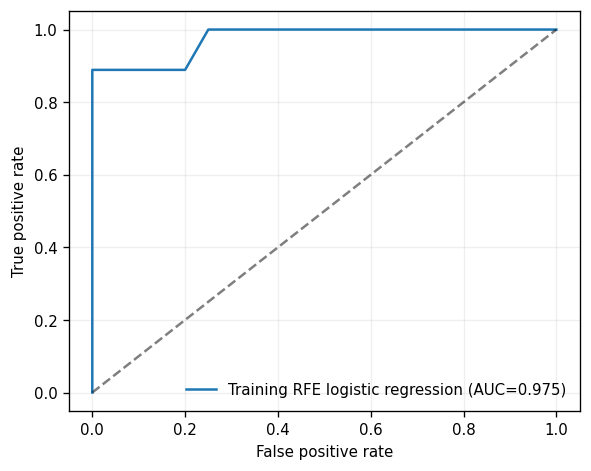

Test RFE logistic regression: accuracy=0.895; balanced accuracy=0.750; AUC=0.850


,pred other,pred bending
actual other,15,0
actual bending,2,2


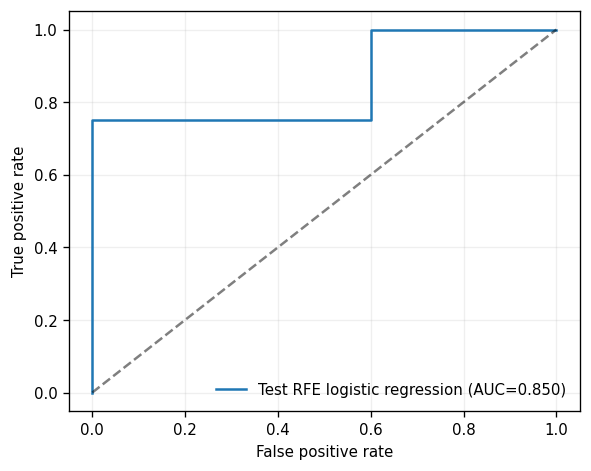

Selected features: ['max_s5_c1']
CV accuracy at chosen pair: 0.9857142857142858
Train accuracy: 0.9855072463768116
Test accuracy: 0.8947368421052632
Smallest fitted probability: 8.251730026333728e-07
Largest fitted probability: 0.9998778297330163
Near-0 or near-1 fitted probabilities (<1e-6 or >1-1e-6): 1
Test versus CV accuracy: 89.47% versus 98.57%; gap = 9.10%.
Selected standardized feature ranges: other= (-2.0413361867251427, 0.8085447869994061) ; bending= (0.12777696657808557, 2.977657940302634)


In [45]:
X_train_best, y_train, _ = all_segment_data(train_keys_ordered, best_l)
X_test_best, y_test, _ = all_segment_data(test_keys_ordered, best_l)
final_pipe = rfe_pipeline(best_p).fit(X_train_best, y_train)
selector = final_pipe.named_steps['rfe']
selected_names = X_train_best.columns[selector.support_].tolist()
scaler = final_pipe.named_steps['standardscaler']
X_train_sel = pd.DataFrame(scaler.transform(X_train_best)[:, selector.support_],
                           columns=selected_names, index=X_train_best.index)
X_test_sel = pd.DataFrame(scaler.transform(X_test_best)[:, selector.support_],
                          columns=selected_names, index=X_test_best.index)
final_lr = final_pipe.named_steps['logisticregression']
train_prob = final_pipe.predict_proba(X_train_best)[:, 1]
train_pred = (train_prob >= .5).astype(int)
test_prob = final_pipe.predict_proba(X_test_best)[:, 1]
test_pred = (test_prob >= .5).astype(int)

coef_table = pd.DataFrame({'feature': ['intercept'] + selected_names,
                           'coefficient_standardized': np.r_[final_lr.intercept_[0], final_lr.coef_[0]]})
display(coef_table)
# Approximate Wald p-values for the selected standardized variables. Post-selection p-values
# are descriptive because the same training data selected the variables.
try:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sm_fit = sm.Logit(y_train, sm.add_constant(X_train_sel, has_constant='add')).fit(disp=False, maxiter=200)
    pvalue_table = pd.DataFrame({'term': sm_fit.params.index,
                                 'coefficient': sm_fit.params.values,
                                 'standard_error': sm_fit.bse.values,
                                 'p_value': sm_fit.pvalues.values})
except Exception as exc:
    pvalue_table = pd.DataFrame({'term': ['unavailable'], 'coefficient': [np.nan],
                                 'standard_error': [np.nan], 'p_value': [np.nan]})
    print('Wald p-values could not be estimated reliably:', str(exc))
display(pvalue_table)

plt.figure(figsize=(5,4))
binary_metrics('Training RFE logistic regression', y_train, train_pred, train_prob)
plt.legend(frameon=False); plt.tight_layout(); plt.show()
plt.figure(figsize=(5,4))
binary_metrics('Test RFE logistic regression', y_test, test_pred, test_prob)
plt.legend(frameon=False); plt.tight_layout(); plt.show()
print('Selected features:', selected_names)
print('CV accuracy at chosen pair:', float(selection_df.iloc[0]['cv_accuracy_mean']))
print('Train accuracy:', accuracy_score(y_train, train_pred))
print('Test accuracy:', accuracy_score(y_test, test_pred))
print('Smallest fitted probability:', float(train_prob.min()))
print('Largest fitted probability:', float(train_prob.max()))
print('Near-0 or near-1 fitted probabilities (<1e-6 or >1-1e-6):',
      int(((train_prob < 1e-6) | (train_prob > 1-1e-6)).sum()))

print(f'Test versus CV accuracy: {accuracy_score(y_test, test_pred):.2%} versus '
      f'{selection_df.iloc[0]["cv_accuracy_mean"]:.2%}; '
      f'gap = {selection_df.iloc[0]["cv_accuracy_mean"] - accuracy_score(y_test, test_pred):.2%}.')
if len(selected_names) == 1:
    col = selected_names[0]
    other_range = (X_train_sel.loc[y_train == 0, col].min(),
                   X_train_sel.loc[y_train == 0, col].max())
    bending_range = (X_train_sel.loc[y_train == 1, col].min(),
                     X_train_sel.loc[y_train == 1, col].max())
    print('Selected standardized feature ranges: other=', other_range,
          '; bending=', bending_range)

The selected model achieves about 98.6% training and cross-validation accuracy,
but only 89.5% test accuracy (17 of 19 recordings). The roughly nine percentage
point gap suggests the selected CV result is optimistic and the test set is also
small. All segmentation and feature selection settings were chosen from training
data, and the test recordings use the same segmentation and selected features.

The fitted classes are strongly separated, but not completely separated in the
selected one-feature model: the feature ranges overlap and one training bending
recording is misclassified. The unpenalized statsmodels fit returns finite
coefficients, standard errors, and p-values. Thus the selected fit does not show
evidence of complete separation causing divergent maximum-likelihood estimates.
Some probabilities are near zero or one, so other, higher-dimensional candidate
models may still be unstable. The sklearn fits use C=1e6 to approximate removing
L2 regularization and a finite iteration limit.

The selected standardized slope is about 4.586 and the intercept is about -4.646;
the corresponding approximate Wald p-values are 0.0052 and 0.0007. The two
coefficient tables distinguish the sklearn fit used for predictions from the
statsmodels maximum-likelihood refit used for inference. Because the training
data also selected the feature, these are descriptive post-selection p-values.

### 2(a)(vii) Class imbalance and case-control sampling

Original bending prevalence=0.130; sampled prevalence=0.500
Intercept correction=-1.897
Case-control, prior-adjusted test model: accuracy=0.947; balanced accuracy=0.875; AUC=0.850


,pred other,pred bending
actual other,15,0
actual bending,1,3


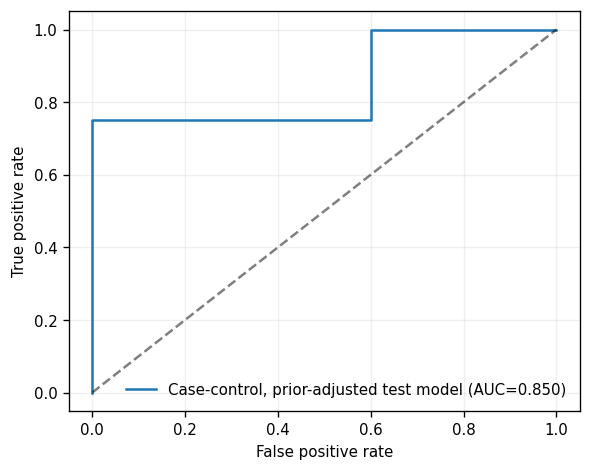

In [48]:

train_bend = np.flatnonzero(y_train == 1)
train_other = np.flatnonzero(y_train == 0)
rng = np.random.default_rng(RANDOM_SEED)
other_sample = rng.choice(train_other, size=len(train_bend), replace=False)
case_control_idx = np.r_[train_bend, other_sample]
case_control_lr = LogisticRegression(solver='liblinear', C=1e6, max_iter=2000,
                                     random_state=RANDOM_SEED)
case_control_lr.fit(X_train_sel.iloc[case_control_idx], y_train[case_control_idx])
pi_original = y_train.mean()
pi_sampled = y_train[case_control_idx].mean()
intercept_correction = np.log(pi_original/(1-pi_original)) - np.log(pi_sampled/(1-pi_sampled))
cc_logit_test = case_control_lr.decision_function(X_test_sel) + intercept_correction
cc_test_prob = 1/(1+np.exp(-cc_logit_test))
cc_test_pred = (cc_test_prob >= .5).astype(int)
print(f'Original bending prevalence={pi_original:.3f}; sampled prevalence={pi_sampled:.3f}')
print(f'Intercept correction={intercept_correction:.3f}')
plt.figure(figsize=(5,4))
binary_metrics('Case-control, prior-adjusted test model', y_test, cc_test_pred, cc_test_prob)
plt.legend(frameon=False); plt.tight_layout(); plt.show()

Bending is the minority class: 9 of 69 training recordings, compared with
60 other activities. The test set contains four bending and 15 other recordings.
The original test confusion matrix misses two of the four bending examples,
showing why overall accuracy alone can conceal poor minority-class recall.

Case-control sampling retains all nine bending cases and randomly selects nine
other recordings. I keep the training-selected features fixed, fit on these 18
recordings, and adjust the fitted intercept by
$\log(\pi/(1-\pi))-\log(\pi_s/(1-\pi_s))$,
where $\pi=9/69$ and $\pi_s=1/2$. This gives an adjustment of about -1.897 and 
the slopes are retained. The adjusted test model correctly classifies 18 of 19
recordings, with bending recall 3/4. An intercept shift changes probabilities
and the classification threshold, but preserves score ordering and hence AUC
for the same fitted slopes. The displayed matrix, ROC, and AUC evaluate this
adjusted model on the original test distribution.

### 2(b)

,l,C,cv_accuracy_mean,cv_accuracy_sd
0,12,1.0,0.9857,0.0319
1,19,10.0,0.9857,0.0319
2,11,1.0,0.9714,0.0391
3,12,10.0,0.9714,0.0391
4,18,10.0,0.9714,0.0391
5,18,1.0,0.9714,0.0391
6,19,100.0,0.9714,0.0391
7,19,1.0,0.9714,0.0391
8,20,10.0,0.9714,0.0391
9,20,1.0,0.9714,0.0391


Chosen l=12, C=1.0; CV accuracy=0.986
Nonzero coefficients: 5
L1 logistic test: accuracy=0.947; balanced accuracy=0.875; AUC=0.983


,pred other,pred bending
actual other,15,0
actual bending,1,3


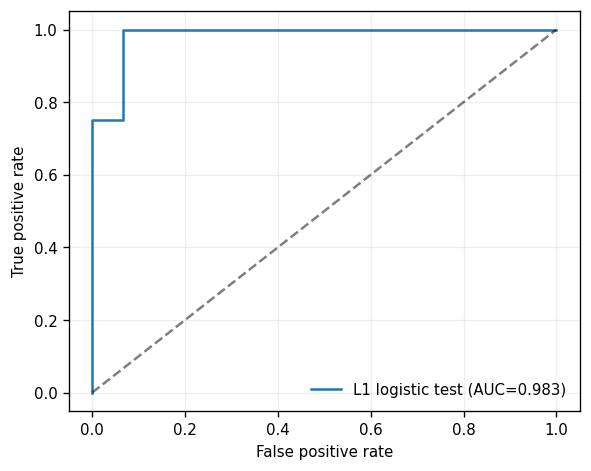

Test accuracy: 0.9473684210526315
RFE selected-model test accuracy: 0.8947368421052632


In [51]:
l1_rows = []
C_grid = [0.001, 0.01, 0.1, 1, 10, 100]
for l in range(1, 21):
    X_l, y_l, _ = all_segment_data(train_keys_ordered, l)
    for C in C_grid:
        estimator = make_pipeline(
            StandardScaler(),
            LogisticRegression(penalty='l1', solver='liblinear', C=C,
                               max_iter=3000, random_state=RANDOM_SEED)
        )
        scores = cross_val_score(estimator, X_l, y_l, cv=cv,
                                 scoring='accuracy', n_jobs=1)
        l1_rows.append({'l': l, 'C': C, 'cv_accuracy_mean': scores.mean(),
                        'cv_accuracy_sd': scores.std(ddof=1)})
l1_cv = pd.DataFrame(l1_rows).sort_values(
    ['cv_accuracy_mean','l','C'], ascending=[False,True,False]).reset_index(drop=True)
display(l1_cv.head(10))
best_l1_l, best_C = int(l1_cv.loc[0,'l']), float(l1_cv.loc[0,'C'])
X_l1_train, y_train, _ = all_segment_data(train_keys_ordered, best_l1_l)
X_l1_test, y_test, _ = all_segment_data(test_keys_ordered, best_l1_l)
l1_model = make_pipeline(StandardScaler(),
    LogisticRegression(penalty='l1', solver='liblinear', C=best_C,
                       max_iter=3000, random_state=RANDOM_SEED)).fit(X_l1_train,y_train)
l1_train_prob = l1_model.predict_proba(X_l1_train)[:,1]
l1_test_prob = l1_model.predict_proba(X_l1_test)[:,1]
l1_train_pred = (l1_train_prob >= .5).astype(int)
l1_test_pred = (l1_test_prob >= .5).astype(int)
print(f'Chosen l={best_l1_l}, C={best_C}; CV accuracy={l1_cv.loc[0,"cv_accuracy_mean"]:.3f}')
print('Nonzero coefficients:', int(np.count_nonzero(l1_model[-1].coef_)))
plt.figure(figsize=(5,4)); binary_metrics('L1 logistic test',y_test,l1_test_pred,l1_test_prob)
plt.legend(frameon=False); plt.tight_layout(); plt.show()
print('Test accuracy:', accuracy_score(y_test,l1_test_pred))
print('RFE selected-model test accuracy:', accuracy_score(y_test,test_pred))

The L1 model selects l=12 and C=1 using the same five stratified folds as RFE.
Its mean CV accuracy is 98.6%, matching RFE's 98.6%. On the held-out test set,
L1 achieves 94.7% (18/19) versus 89.5% (17/19) for RFE; its test AUC is
also higher (about 0.983 versus 0.850). Thus L1 performs better on this split,
although the accuracy difference is just one recording.

The assignment permits backward selection as an alternative to pruning by
p-values; I use RFE for that alternative and report p-values for its final refit.
L1 is easier to implement than repeated p-value-based fitting and pruning:
regularization and feature selection happen in one estimator, with C controlling
penalty strength. Scaling is fitted inside each CV fold. RFE explicitly controls
the retained feature count, but requires repeated fitting. Neither method's
best tuning score is an unbiased estimate after searching the same folds.

### 2(c)

Five-fold multiclass CV: bending2 has four training recordings; one validation fold lacks bending2, but every training fold has all classes.


**Multiclass validation-fold class counts:**

,bending1,bending2,cycling,lying,sitting,standing,walking
fold 1,1,1,3,2,2,3,2
fold 2,1,1,2,3,2,3,2
fold 3,1,1,2,3,2,2,3
fold 4,1,1,2,2,3,2,3
fold 5,1,0,3,2,3,2,2


,l,C,cv_accuracy_mean,cv_accuracy_sd
0,1,1.0,0.8989,0.0810
1,2,1.0,0.8846,0.0377
2,3,10.0,0.8846,0.0630
3,2,10.0,0.8835,0.0414
4,4,10.0,0.8714,0.0782
5,1,10.0,0.8692,0.0606
6,5,10.0,0.8692,0.0335
7,4,1.0,0.8571,0.1010
8,5,1.0,0.8560,0.0486
9,3,1.0,0.8549,0.0876


Multinomial L1: l=1, C=1.0, CV accuracy=0.899
Test accuracy: 0.9473684210526315  test error: 0.052631578947368474


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.95      0.95        19
weighted avg       0.96      0.95      0.95        19



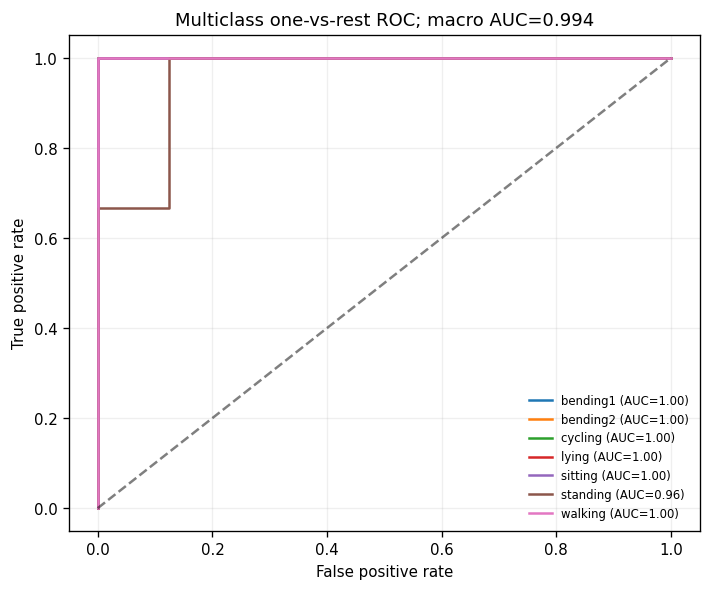

**Training-CV choices for each Naive Bayes model:**

,model,l,cv_accuracy_mean,cv_accuracy_sd
0,Gaussian Naive Bayes,1,0.8978,0.0830
9,Multinomial Naive Bayes,5,0.7670,0.0655


**Gaussian Naive Bayes: test confusion matrix (true rows, predicted columns)**

,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


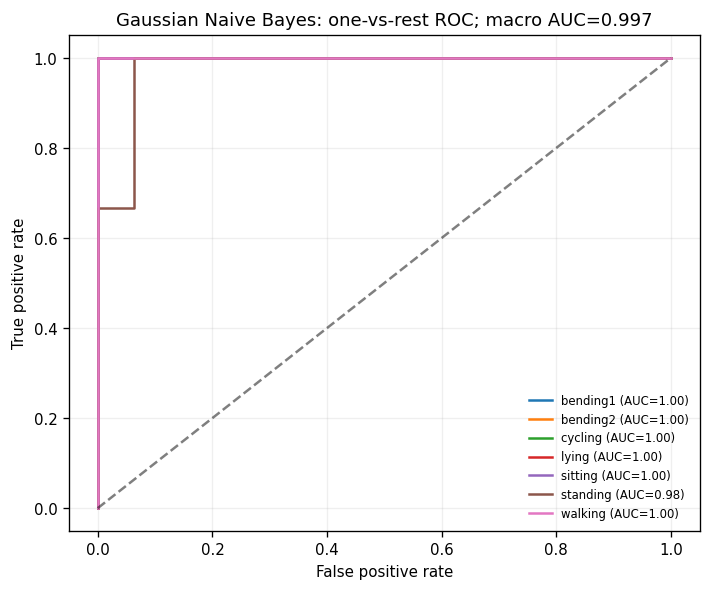

**Multinomial Naive Bayes: test confusion matrix (true rows, predicted columns)**

,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,0,1,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


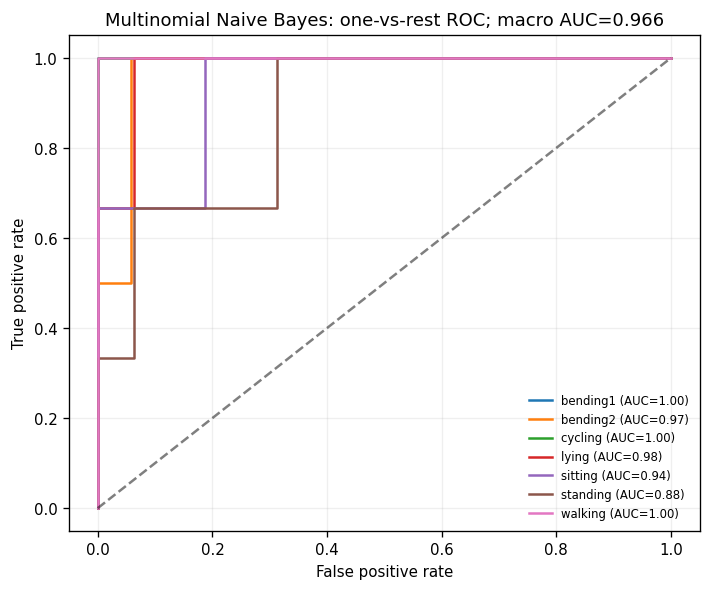

**Multiclass comparison: all settings selected using training CV**

,model,l,cv_accuracy,test_accuracy,test_error,test_macro_auc
0,Multinomial L1 logistic,1,0.8989,0.9474,0.0526,0.994
1,Gaussian Naive Bayes,1,0.8978,0.8947,0.1053,0.997
2,Multinomial Naive Bayes,5,0.7670,0.7895,0.2105,0.966


The strongest training-CV model is Multinomial L1 logistic (CV accuracy 89.89%). The highest observed test accuracy is Multinomial L1 logistic (94.74%; error 5.26%). Model settings are selected by training CV, and test results are used only for final comparison.

In [54]:
# Five folds are required, but bending2 has only four training recordings.
# Consequently one validation fold cannot contain bending2. Every TRAINING
# fold still contains all seven classes, and accuracy remains defined.
X_mc_base, y_mc_base, _ = all_segment_data(train_keys_ordered, 1, binary=False)
mc_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=UserWarning,
                            message='The least populated class in y has only.*')
    mc_cv = list(mc_splitter.split(X_mc_base, y_mc_base))
assert all(len(np.unique(y_mc_base[tr])) == 7 for tr, va in mc_cv)
print('Five-fold multiclass CV: bending2 has four training recordings; '
      'one validation fold lacks bending2, but every training fold has all classes.')
fold_counts = pd.DataFrame([
    pd.Series(y_mc_base[va]).value_counts().reindex(activities, fill_value=0)
    for tr, va in mc_cv], index=[f'fold {i}' for i in range(1, 6)])
display(Markdown('**Multiclass validation-fold class counts:**'))
display(fold_counts)

# Tune multinomial L1 logistic regression over l and C with training-only CV.
mc_rows = []
mc_C_grid = [0.01, 0.1, 1, 10]
for l in range(1, 21):
    X_l, y_mc, _ = all_segment_data(train_keys_ordered, l, binary=False)
    for C in mc_C_grid:
        estimator = make_pipeline(StandardScaler(),
            LogisticRegression(penalty='l1', solver='saga', C=C,
                               max_iter=2000, tol=1e-3, random_state=RANDOM_SEED))
        scores = cross_val_score(estimator, X_l, y_mc, cv=mc_cv,
                                 scoring='accuracy', n_jobs=1)
        mc_rows.append({'l': l, 'C': C, 'cv_accuracy_mean': scores.mean(),
                        'cv_accuracy_sd': scores.std(ddof=1)})
mc_cv_table = pd.DataFrame(mc_rows).sort_values(
    ['cv_accuracy_mean','l','C'], ascending=[False,True,False]).reset_index(drop=True)
display(mc_cv_table.head(10))
best_mc_l, best_mc_C = int(mc_cv_table.loc[0,'l']), float(mc_cv_table.loc[0,'C'])
X_mc_train, y_mc_train, meta_mc_train = all_segment_data(train_keys_ordered,best_mc_l,binary=False)
X_mc_test, y_mc_test, meta_mc_test = all_segment_data(test_keys_ordered,best_mc_l,binary=False)
mc_model = make_pipeline(StandardScaler(),
    LogisticRegression(penalty='l1', solver='saga', C=best_mc_C,
                       max_iter=2000, tol=1e-3, random_state=RANDOM_SEED)).fit(X_mc_train,y_mc_train)
mc_prob = mc_model.predict_proba(X_mc_test)
mc_pred = mc_model.predict(X_mc_test)
class_names = mc_model[-1].classes_
mc_cm = confusion_matrix(y_mc_test,mc_pred,labels=class_names)
print(f'Multinomial L1: l={best_mc_l}, C={best_mc_C}, '
      f'CV accuracy={mc_cv_table.loc[0,"cv_accuracy_mean"]:.3f}')
print('Test accuracy:', accuracy_score(y_mc_test,mc_pred),
      ' test error:', 1-accuracy_score(y_mc_test,mc_pred))
display(pd.DataFrame(mc_cm,index=class_names,columns=class_names))
print(classification_report(y_mc_test,mc_pred,labels=class_names,
      target_names=[str(a) for a in class_names],zero_division=0))
# Multiclass ROC with one-vs-rest class curves and macro AUC.
y_mc_bin = label_binarize(y_mc_test, classes=class_names)
macro_auc = roc_auc_score(y_mc_bin, mc_prob, average='macro', multi_class='ovr')
plt.figure(figsize=(6,5))
for k, name in enumerate(class_names):
    if len(np.unique(y_mc_bin[:,k])) == 2:
        fpr, tpr, _ = roc_curve(y_mc_bin[:,k],mc_prob[:,k])
        auc_k = roc_auc_score(y_mc_bin[:,k],mc_prob[:,k])
        plt.plot(fpr,tpr,label=f'{name} (AUC={auc_k:.2f})')
plt.plot([0,1],[0,1],'k--',alpha=.5); plt.xlabel('False positive rate')
plt.ylabel('True positive rate'); plt.title(f'Multiclass one-vs-rest ROC; macro AUC={macro_auc:.3f}')
plt.legend(fontsize=7,frameon=False); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

# Tune l independently for each Naive Bayes model on training data only.
nb_search_rows = []
for l in range(1, 21):
    X_l, y_l, _ = all_segment_data(train_keys_ordered, l, binary=False)
    candidates = {
        'Gaussian Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
        # clip=True prevents test features outside the training range from
        # becoming negative. This scaler is fitted separately within each fold.
        'Multinomial Naive Bayes': make_pipeline(MinMaxScaler(clip=True), MultinomialNB())
    }
    for name, estimator in candidates.items():
        scores = cross_val_score(estimator, X_l, y_l, cv=mc_cv,
                                 scoring='accuracy', n_jobs=1)
        nb_search_rows.append({'model': name, 'l': l,
                              'cv_accuracy_mean': scores.mean(),
                              'cv_accuracy_sd': scores.std(ddof=1)})
nb_cv_table = pd.DataFrame(nb_search_rows).sort_values(
    ['model', 'cv_accuracy_mean', 'l'], ascending=[True, False, True])
nb_best = nb_cv_table.groupby('model', sort=False).head(1)
display(Markdown('**Training-CV choices for each Naive Bayes model:**'))
display(nb_best)

model_rows = [{'model': 'Multinomial L1 logistic', 'l': best_mc_l,
               'cv_accuracy': mc_cv_table.iloc[0]['cv_accuracy_mean'],
               'test_accuracy': accuracy_score(y_mc_test, mc_pred),
               'test_error': 1 - accuracy_score(y_mc_test, mc_pred),
               'test_macro_auc': macro_auc}]
nb_models = {}
for _, best in nb_best.iterrows():
    name, l = best['model'], int(best['l'])
    X_nb_train, y_nb_train, _ = all_segment_data(train_keys_ordered, l, binary=False)
    X_nb_test, y_nb_test, _ = all_segment_data(test_keys_ordered, l, binary=False)
    estimator = (make_pipeline(StandardScaler(), GaussianNB())
                 if name == 'Gaussian Naive Bayes'
                 else make_pipeline(MinMaxScaler(clip=True), MultinomialNB()))
    estimator.fit(X_nb_train, y_nb_train)
    nb_models[name] = estimator
    nb_pred = estimator.predict(X_nb_test)
    nb_prob = estimator.predict_proba(X_nb_test)
    nb_classes = estimator[-1].classes_
    nb_truth = label_binarize(y_nb_test, classes=nb_classes)
    nb_auc = roc_auc_score(nb_truth, nb_prob, average='macro')
    model_rows.append({'model': name, 'l': l,
                       'cv_accuracy': best['cv_accuracy_mean'],
                       'test_accuracy': accuracy_score(y_nb_test, nb_pred),
                       'test_error': 1 - accuracy_score(y_nb_test, nb_pred),
                       'test_macro_auc': nb_auc})
    display(Markdown(f'**{name}: test confusion matrix (true rows, predicted columns)**'))
    display(pd.DataFrame(confusion_matrix(y_nb_test, nb_pred, labels=nb_classes),
                         index=nb_classes, columns=nb_classes))
    plt.figure(figsize=(6, 5))
    for k, label in enumerate(nb_classes):
        fpr, tpr, _ = roc_curve(nb_truth[:, k], nb_prob[:, k])
        auc_k = roc_auc_score(nb_truth[:, k], nb_prob[:, k])
        plt.plot(fpr, tpr, label=f'{label} (AUC={auc_k:.2f})')
    plt.plot([0, 1], [0, 1], 'k--', alpha=.5)
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
    plt.title(f'{name}: one-vs-rest ROC; macro AUC={nb_auc:.3f}')
    plt.legend(fontsize=7, frameon=False); plt.grid(alpha=.2)
    plt.tight_layout(); plt.show()

model_comparison = pd.DataFrame(model_rows).sort_values(
    'cv_accuracy', ascending=False).reset_index(drop=True)
display(Markdown('**Multiclass comparison: all settings selected using training CV**'))
display(model_comparison)
cv_winner = model_comparison.iloc[0]
test_winner = model_comparison.sort_values('test_accuracy', ascending=False).iloc[0]
display(Markdown(
    f"The strongest training-CV model is {cv_winner['model']} "
    f"(CV accuracy {cv_winner['cv_accuracy']:.2%}). "
    f"The highest observed test accuracy is {test_winner['model']} "
    f"({test_winner['test_accuracy']:.2%}; error {test_winner['test_error']:.2%}). "
    "Model settings are selected by training CV, and test results are used only for final comparison."
))

For multiclass classification, the confusion matrix has one row per true
activity and one column per predicted activity; diagonal entries are correct
predictions. The seven one-versus-rest ROC curves each treat one activity as
positive and the other six as negative, using that activity's predicted
probability. Each curve plots sensitivity against false-positive rate as the
threshold varies. Macro AUC gives each activity equal weight.

I tune l separately for multinomial L1 logistic regression, Gaussian Naive Bayes,
and Multinomial Naive Bayes, using the same five training folds.
Because bending2 has only four training recordings, five validation folds cannot
all contain that class. Stratification distributes those four recordings across
four validation folds; every training fold still includes all seven activities.
I retain the requested five-fold scheme and use accuracy, which is defined even
when a validation fold lacks one class. The displayed fold-count table makes
this limitation explicit. The comparison
table reports each model's chosen l, CV accuracy, test error, and macro AUC; the
text immediately below it identifies the best results explicitly.

Gaussian Naive Bayes models each continuous feature by a Gaussian distribution
within each activity. Multinomial Naive Bayes uses a multinomial likelihood
for nonnegative feature weights; these are likelihood assumptions rather than
Gaussian versus multinomial class priors. Both use class frequencies as their
default class priors. The latter's count-like assumption is less natural for
continuous RSS summary statistics. I fit min-max scaling within each fold and
clip held-out values to the training range to guarantee nonnegative inputs.
This produces a valid numerical comparison, though scaling does not turn sensor
summaries into actual counts. The test set has only 19 recordings, so small
accuracy differences should be interpreted cautiously.

Multinomial L1 logistic regression has the highest CV accuracy (89.89%) and
test accuracy (94.74%) among these three models. Gaussian Naive Bayes has the
highest test macro AUC (about 0.997 versus 0.994 for logistic regression), despite
its lower test accuracy (89.47%). This is consistent: ROC/AUC evaluates the
ranking of each class against the rest over thresholds, whereas test accuracy
evaluates the single class with the highest predicted probability. Multinomial
Naive Bayes has 78.95% test accuracy and macro AUC about 0.966.


## ISLR 4.8.3




For class \(k\), the conditional density is

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

The Bayes classifier assigns \(x\) to the class that maximizes $\pi_k f_k(x)$, where $\pi_k$ is the prior probability of class \(k\). Taking the logarithm and dropping the common constant gives the discriminant

$$
\delta_k(x)
=
\log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the square,

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k).
$$

Because $\sigma_k^2$ differs by class, the coefficient of \(x^2\) generally differs as well. Therefore, the quadratic terms do not cancel when comparing classes, and the decision boundary is generally quadratic in \(x\). If all classes had the same variance, the quadratic terms would cancel and the boundary would be linear.

## ISLR 4.8.7

The class priors and conditional distributions are

$$
P(\text{Yes})=0.8,\qquad P(\text{No})=0.2,
$$

$$
X\mid \text{Yes}\sim N(10,36),\qquad
X\mid \text{No}\sim N(0,36).
$$

By Bayes’ theorem,

$$
P(\text{Yes}\mid X=4)
=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

The two distributions have the same variance, so their common density constant cancels. The density ratio is

$$
\frac{f_{\text{Yes}}(4)}{f_{\text{No}}(4)}
=
\exp\left(
-\frac{(4-10)^2}{72}
+\frac{(4-0)^2}{72}
\right)
=
\exp\left(-\frac{5}{18}\right).
$$

Thus,

$$
P(\text{Yes}\mid X=4)
=
\frac{0.8e^{-5/18}}
{0.8e^{-5/18}+0.2}
\approx 0.7519.
$$

The predicted probability that the company will issue a dividend is approximately 75.19%.